 //explicacion del dataset y grupo  

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

// Importacion del data set

In [2]:
dataset = pd.read_csv('./dataset/listings.csv')
dataset.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 29685 entries, 0 to 29684
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            29685 non-null  int64  
 1   listing_url                                   29685 non-null  str    
 2   scrape_id                                     29685 non-null  int64  
 3   last_scraped                                  29685 non-null  str    
 4   source                                        29685 non-null  str    
 5   name                                          29685 non-null  str    
 6   description                                   28917 non-null  str    
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   29684 non-null  str    
 9   host_id                                       29685 non-null  int64  
 1

a priori vemos que las siguientes variables no presentan valores, es decir, estan vacías (codigo de abajo).


In [3]:

vacias = dataset.columns[dataset.isna().all()]
print(len(vacias), "columnas vacías:")
for col in vacias:
    print("-", col)

13 columnas vacías:
- neighborhood_overview
- host_since
- host_response_time
- host_response_rate
- host_acceptance_rate
- host_thumbnail_url
- host_neighbourhood
- host_total_listings_count
- host_verifications
- neighbourhood
- neighbourhood_group_cleansed
- calendar_updated
- instant_bookable


//introducción, mostrar tablas y contar que se borra y la tabla desp de la limpieza. 
Empezamos por las columnas vacias

In [4]:
dataset_limpio = dataset.drop(columns=vacias)
print(dataset.shape, "->", dataset_limpio.shape)
print("\n")
dataset_limpio.info()

(29685, 90) -> (29685, 77)


<class 'pandas.DataFrame'>
RangeIndex: 29685 entries, 0 to 29684
Data columns (total 77 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            29685 non-null  int64  
 1   listing_url                                   29685 non-null  str    
 2   scrape_id                                     29685 non-null  int64  
 3   last_scraped                                  29685 non-null  str    
 4   source                                        29685 non-null  str    
 5   name                                          29685 non-null  str    
 6   description                                   28917 non-null  str    
 7   picture_url                                   29684 non-null  str    
 8   host_id                                       29685 non-null  int64  
 9   host_url                                   

In [5]:
dataset_limpio.describe() #describe no toma en cuenta los string, por eso las 48 rows

,id,scrape_id,host_id,host_profile_id,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_listings_count,latitude,...,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
count,2.968500e+04,2.968500e+04,2.968500e+04,2.968500e+04,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,...,25957.000000,25957.000000,25957.000000,25957.000000,25957.000000,29685.000000,29685.000000,29685.000000,29685.000000,25957.000000
mean,9.329954e+17,2.026063e+13,1.081103e+16,1.476728e+18,7.506687,5.532727,5.323362,5.461142,19.602964,-34.592114,...,4.742028,4.869180,4.862890,4.874793,4.740904,15.194240,14.214654,0.701937,0.057773,1.481166
std,5.838355e+17,0.000000e+00,1.347071e+17,3.962312e+16,4.083517,3.376887,4.046868,3.296444,44.760560,0.017920,...,0.371037,0.291209,0.304637,0.244150,0.375315,32.782011,32.632849,3.608907,0.735822,1.640487
min,1.150800e+04,2.026063e+13,1.342600e+04,1.462507e+18,0.000000,0.000000,0.000000,0.000000,0.000000,-34.690056,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.010000
25%,6.233293e+17,2.026063e+13,3.506745e+07,1.462945e+18,4.000000,3.000000,2.000000,3.000000,1.000000,-34.603396,...,4.670000,4.850000,4.850000,4.850000,4.680000,1.000000,1.000000,0.000000,0.000000,0.370000
50%,1.046350e+18,2.026063e+13,1.585246e+08,1.467135e+18,8.000000,5.000000,4.000000,5.000000,3.000000,-34.591459,...,4.830000,4.950000,4.950000,4.940000,4.830000,3.000000,2.000000,0.000000,0.000000,0.980000
75%,1.431417e+18,2.026063e+13,4.644293e+08,1.470093e+18,11.000000,8.000000,8.000000,8.000000,16.000000,-34.581430,...,4.950000,5.000000,5.000000,5.000000,4.940000,12.000000,10.000000,0.000000,0.000000,2.050000
max,1.717830e+18,2.026063e+13,1.716955e+18,1.716967e+18,17.000000,11.000000,15.000000,11.000000,1375.000000,-34.534980,...,5.000000,5.000000,5.000000,5.000000,5.000000,208.000000,208.000000,52.000000,18.000000,41.660000


In [6]:
dataset_limpio.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,picture_url,host_id,host_url,...,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,54019695,https://www.airbnb.com/rooms/54019695,20260629030533,2026-07-02,city scrape,Hermoso departamento con piscina en Puerto Mad...,Enjoy a stylish experience in this centrally-l...,https://a0.muscache.com/pictures/miso/Hosting-...,298874610,https://www.airbnb.com/users/show/298874610,...,NaN,NaN,NaN,NaN,NaN,24,24,0,0,NaN
1,41720307,https://www.airbnb.com/rooms/41720307,20260629030533,2026-06-29,city scrape,"Departamento dos ambientes, 2cuadras recoleta ...",Brand new remodeled apartment 2 blocks from th...,https://a0.muscache.com/pictures/37e687e2-2587...,220409424,https://www.airbnb.com/users/show/220409424,...,4.67,4.67,4.67,4.56,NaN,8,8,0,0,0.16
2,1090530711732696379,https://www.airbnb.com/rooms/1090530711732696379,20260629030533,2026-07-02,previous scrape,"alquiler mensual ,escenografico.",This place is strategically located - it will ...,https://a0.muscache.com/pictures/3adbe27a-af59...,488443857,https://www.airbnb.com/users/show/488443857,...,4.67,4.67,5.00,4.67,NaN,3,1,2,0,0.34
3,1482653002662185299,https://www.airbnb.com/rooms/1482653002662185299,20260629030533,2026-07-02,city scrape,Descanso ideal - Av. Sante Fe,"Large and comfortable apartment for 4 people, ...",https://a0.muscache.com/pictures/hosting/Hosti...,283840529,https://www.airbnb.com/users/show/283840529,...,4.95,4.95,4.89,4.89,NaN,12,12,0,0,1.78
4,1046394538968941382,https://www.airbnb.com/rooms/1046394538968941382,20260629030533,2026-06-29,city scrape,Excelente zona,Enjoy easy access to everything from this perf...,https://a0.muscache.com/pictures/hosting/Hosti...,550970409,https://www.airbnb.com/users/show/550970409,...,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN


Ahora siguen las variables que no nos dicen nada.


In [7]:
por_host = dataset_limpio.groupby("host_has_profile_pic")["host_id"].nunique()
porcentaje = (por_host / por_host.sum() * 100).round(1)

display(pd.DataFrame({"hosts": por_host, "%": porcentaje}))



,hosts,%
host_has_profile_pic,,
f,826,5.7
t,13730,94.3


El 94,3 % de los hosts (13.730) tiene foto de perfil y solo el 5,7 % (826) no.
Como casi no distingue entre publicaciones, la descartamos por ser una
variable cuasi-constante.

In [8]:
scrape = dataset_limpio["scrape_id"].nunique()
scrape

1

La variable scrape_id tiene un único valor: todos los datos son de un mismo
relevamiento (realizado entre el 29/06 y el 02/07 de 2026). Por eso no aporta
información y la descartamos.

In [9]:
dataset_limpio = dataset_limpio.set_index("id")
a_borrar = ["listing_url", "scrape_id", "picture_url", "host_url",
            "host_picture_url", "host_has_profile_pic", "host_thumbnail_url"]

ya_borradas = [c for c in a_borrar if c not in dataset_limpio.columns]
print("Ya no estaban:", ya_borradas)

dataset_limpio = dataset_limpio.drop(columns=[c for c in a_borrar if c in dataset_limpio.columns])
print(dataset_limpio.shape)

Ya no estaban: ['host_thumbnail_url']
(29685, 70)


// depuracion de la base (variables no utilizables,columnas enteramente nulas..)

//Parte mia wachines (integrante 2, desp vemos como lo acomodamos)

## Hipotesis C
Como la independencia no está en la base, la construimos como proporciones por huésped (camas y baños por persona), así comparamos alojamientos de distinto tamaño en igualdad de condiciones.

In [10]:
analisis = dataset_limpio[["price", "accommodates", "beds", "bathrooms"]].copy()

analisis["camas_por_huesped"] = analisis["beds"] / analisis["accommodates"]
analisis["banos_por_huesped"] = analisis["bathrooms"] / analisis["accommodates"]

analisis.sample(8, random_state=1)

,price,accommodates,beds,bathrooms,camas_por_huesped,banos_por_huesped
id,,,,,,
1279676021624019583,NaN,4,NaN,NaN,NaN,NaN
1715616593278717831,"$79,089.31",2,1.0,1.0,0.500000,0.500000
1033535818436194431,"$68,897.80",2,1.0,1.0,0.500000,0.500000
1478580480404417074,"$134,058.93",2,1.0,1.0,0.500000,0.500000
999401349862816370,"$100,793.15",3,3.0,1.0,1.000000,0.333333
1319507706668270204,"$77,999.50",3,2.0,1.0,0.666667,0.333333
1693835884089961711,"$84,993.50",2,1.0,1.0,0.500000,0.500000
1700363744819809998,"$119,252.88",3,3.0,1.0,1.000000,0.333333


Pasamos price a número (venía como texto con $ y comas) y lo guardamos
en precio. Después revisamos faltantes y valores extremos: hay datos
vacíos en precio, camas y baños, y algunos valores raros (por ejemplo,
precios de más de 171 millones por noche). Los vamos a tratar antes de
armar el modelo, porque pueden distorsionar los resultados.

In [11]:
analisis["precio"] = analisis["price"].str.replace(r"[\$,]", "", regex=True).astype(float)

print(analisis.isna().sum())
analisis.describe().T

price                1792
accommodates            0
beds                 2583
bathrooms            3441
camas_por_huesped    2583
banos_por_huesped    3441
precio               1792
dtype: int64


,count,mean,std,min,25%,50%,75%,max
accommodates,29685.0,2.941654,1.584278e+00,1.0000,2.000000,2.00,4.00,16.0
beds,27102.0,1.947753,1.621595e+00,1.0000,1.000000,1.00,2.00,50.0
bathrooms,26244.0,1.244494,7.039866e-01,0.5000,1.000000,1.00,1.00,22.0
camas_por_huesped,27102.0,0.663341,4.148025e-01,0.0625,0.500000,0.50,0.75,25.0
banos_por_huesped,26244.0,0.496740,4.141480e-01,0.0625,0.333333,0.50,0.50,20.0
precio,27893.0,275831.944428,3.622302e+06,1215.5000,75274.570000,100631.33,140480.93,171643781.0


### Tratamiento de faltantes

Eliminamos las filas con datos vacíos en precio, camas o baños, ya que la
regresión no puede usarlas. No imputamos porque camas y baños son justamente
las variables que queremos medir, y rellenarlas sería inventar el dato. Nos
quedamos con 25.256 publicaciones (85 % del total).

In [12]:
analisis_modelo = analisis.dropna(subset=["precio", "beds", "bathrooms"])
print(analisis.shape, "->", analisis_modelo.shape)

(29685, 7) -> (25256, 7)


### Valores extremos en camas y baños por huésped

Encontramos 291 publicaciones con más de 2 camas o 2 baños por huésped.
Casi todas son habitaciones privadas, compartidas o de hotel, donde camas y
baños probablemente se cuentan para toda la propiedad y no para la
habitación. Por eso esas proporciones no miden independencia y las
excluimos.

In [13]:
analisis_modelo["room_type"] = dataset_limpio["room_type"]

raros = analisis_modelo[(analisis_modelo["camas_por_huesped"] > 2) |
                        (analisis_modelo["banos_por_huesped"] > 2)]
print(len(raros))
raros["room_type"].value_counts()

291


room_type
Private room       227
Shared room         42
Entire home/apt     17
Hotel room           5
Name: count, dtype: int64

In [14]:
analisis_modelo = analisis_modelo[(analisis_modelo["camas_por_huesped"] <= 2) &
                                  (analisis_modelo["banos_por_huesped"] <= 2)]
print(len(analisis_modelo))

24965


### Valores extremos en el precio

Hay precios de hasta 171 millones por noche, que casi seguro son errores de
carga, y distorsionan los resultados de la regresión. Nos quedamos con el 99 %
central de los precios (entre los percentiles 0,5 y 99,5), que deja afuera
los casos más extremos.

In [15]:
p_bajo, p_alto = analisis_modelo["precio"].quantile([0.005, 0.995])
print(p_bajo, p_alto)

analisis_modelo = analisis_modelo[analisis_modelo["precio"].between(p_bajo, p_alto)]
print(len(analisis_modelo))

22824.0 1572099.6332000108
24716


El precio sigue muy asimétrico, la mayoría de los alojamientos son baratos
o medianos y unos pocos son carísimos. Por eso trabajamos con el logaritmo
del precio, que lo deja mucho más simétrico y ayuda a que la regresión
funcione bien. Además los resultados se leen en porcentaje.

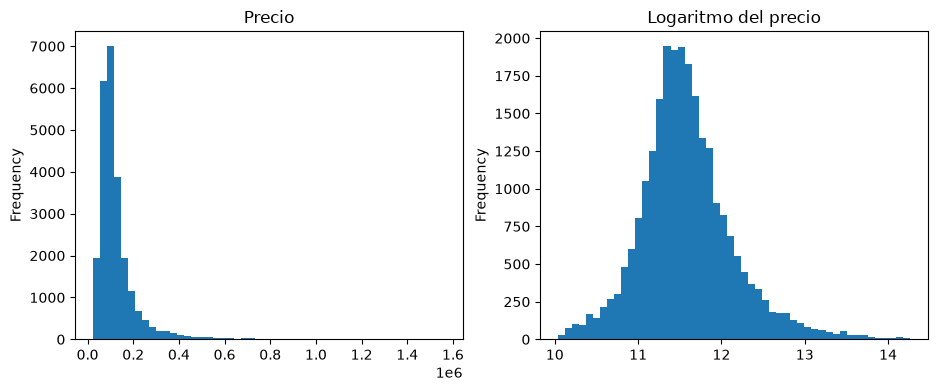

In [16]:
analisis_modelo["log_precio"] = np.log(analisis_modelo["precio"])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
analisis_modelo["precio"].plot.hist(bins=50, ax=ax[0])
ax[0].set_title("Precio")
analisis_modelo["log_precio"].plot.hist(bins=50, ax=ax[1])
ax[1].set_title("Logaritmo del precio")
plt.show()

### Modelo 1: regresión lineal múltiple

Ajustamos una regresión con el logaritmo del precio como variable a explicar,
y la capacidad, las camas por huésped y los baños por huésped como variables
explicativas. El modelo explica cerca del 28 % de la variación del precio
(R² = 0,277). La capacidad tiene un efecto positivo y significativo; las camas
por huésped, un efecto negativo que resulta significativo con el cálculo
habitual (más adelante lo volvemos a revisar); y los baños por huésped no
resultan significativos. Todavía no hay controles por ubicación ni tipo de
alojamiento.

In [17]:
modelo1 = smf.ols("log_precio ~ accommodates + camas_por_huesped + banos_por_huesped",
                  data=analisis_modelo).fit()
print(modelo1.summary())

                            OLS Regression Results                            
Dep. Variable:             log_precio   R-squared:                       0.277
Model:                            OLS   Adj. R-squared:                  0.277
Method:                 Least Squares   F-statistic:                     3163.
Date:                Fri, 06 Nov 2026   Prob (F-statistic):               0.00
Time:                        21:30:42   Log-Likelihood:                -16656.
No. Observations:               24716   AIC:                         3.332e+04
Df Residuals:                   24712   BIC:                         3.335e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            11.1324      0.01

### Modelo 2: controles por tipo de alojamiento y barrio

Agregamos como controles el tipo de alojamiento y el barrio, para comparar
alojamientos similares entre sí. El R² sube a 0,397. Con estos controles los
baños por huésped pasan a tener un efecto positivo y significativo sobre el
precio, mientras que las camas por huésped mantienen un efecto negativo muy
pequeño (que, como vemos más adelante, deja de ser significativo al tener en
cuenta a los hosts). El cambio en los baños se debe a que, sin controlar, se
mezclaban habitaciones y departamentos enteros, que tienen precios muy
distintos.

In [18]:
analisis_modelo["barrio"] = dataset_limpio["neighbourhood_cleansed"]

modelo2 = smf.ols("log_precio ~ accommodates + camas_por_huesped + banos_por_huesped + C(room_type) + C(barrio)",
                  data=analisis_modelo).fit()

tabla = pd.DataFrame({"coef": modelo2.params, "p-valor": modelo2.pvalues})
print("R²:", round(modelo2.rsquared, 3))
tabla[~tabla.index.str.contains("barrio")].round(4)

R²: 0.397


,coef,p-valor
Intercept,10.8535,0.0000
C(room_type)[T.Hotel room],0.7752,0.0000
C(room_type)[T.Private room],-0.4377,0.0000
C(room_type)[T.Shared room],-0.9115,0.0000
accommodates,0.1865,0.0000
camas_por_huesped,-0.0265,0.0207
banos_por_huesped,0.2248,0.0000


### Multicolinealidad (VIF)

Calculamos el VIF de las variables numéricas del modelo para ver si alguna
está demasiado relacionada con las otras. Todos los valores quedaron por
debajo de 1,4, muy lejos del umbral de 5, por lo que no hay problemas de
multicolinealidad.

In [19]:
X = add_constant(analisis_modelo[["accommodates", "camas_por_huesped", "banos_por_huesped"]])

vif = pd.DataFrame({
    "variable": X.columns,
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
})
vif[vif["variable"] != "const"].round(2)

,variable,VIF
1,accommodates,1.34
2,camas_por_huesped,1.06
3,banos_por_huesped,1.38


### Homocedasticidad

La regresión supone que los errores tienen una dispersión parecida para todos
los precios. Para revisarlo graficamos los residuos (la diferencia entre el
precio real y el predicho) contra los valores ajustados. Si se cumple el
supuesto, tendríamos que ver una nube pareja alrededor del cero.

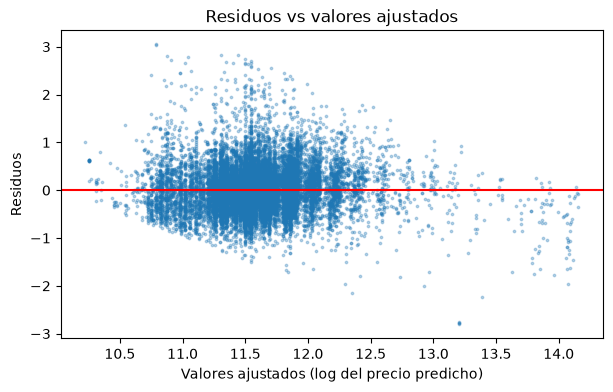

In [20]:
residuos = modelo2.resid
ajustados = modelo2.fittedvalues

plt.figure(figsize=(7, 4))
plt.scatter(ajustados, residuos, s=3, alpha=0.3)
plt.axhline(0, color="red")
plt.xlabel("Valores ajustados (log del precio predicho)")
plt.ylabel("Residuos")
plt.title("Residuos vs valores ajustados")
plt.show()

La dispersión de los residuos es algo mayor en los extremos que en el centro,
por lo que el supuesto de varianza constante se cumple de forma aproximada
pero no perfecta. Lo tenemos en cuenta al interpretar los p-valores.

### Normalidad de los residuos

Otro supuesto de la regresión es que los residuos se distribuyen de forma
normal. Lo revisamos con el test de Shapiro-Wilk, aplicado sobre una muestra
de 5.000 residuos (el test está pensado para ese tamaño), y con un gráfico
Q-Q.

Shapiro-Wilk: ShapiroResult(statistic=np.float64(0.9505020971201738), pvalue=np.float64(4.1079257326202803e-38))


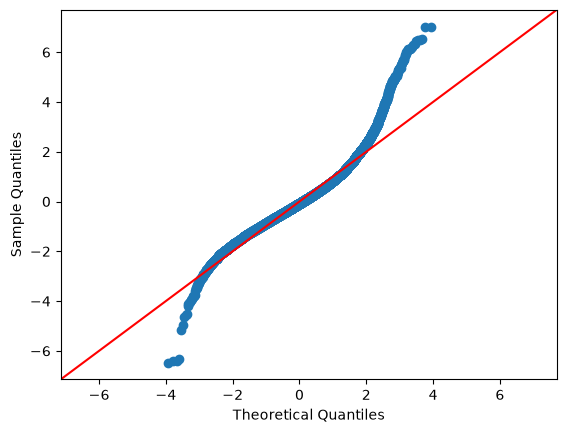

In [21]:
muestra = modelo2.resid.sample(5000, random_state=1)
print("Shapiro-Wilk:", stats.shapiro(muestra))

sm.qqplot(modelo2.resid, line="45", fit=True)
plt.show()

El test de Shapiro-Wilk rechaza la normalidad y el gráfico Q-Q muestra desvíos
en las colas, sobre todo en la derecha: hay alojamientos mucho más caros de lo
que predice el modelo. Dado el gran tamaño de la muestra, consideramos que
esto no invalida los resultados, pero lo tomamos como una limitación.

### Conclusión de la hipótesis C

La hipótesis decía que, a igual capacidad, un alojamiento se alquila más
caro si da más independencia: una cama por persona, más baños por huésped
y reserva automática. Para probarla usamos una regresión lineal múltiple
sobre el logaritmo del precio, controlando por capacidad, tipo de
alojamiento y barrio (24.716 publicaciones, R² = 0,397).

Encontramos:
- Baños por huésped: efecto positivo y significativo (coeficiente 0,22).
  Pasar de 0,5 a 1 baño por huésped (por ejemplo, de 1 a 2 baños para
  2 personas) se asocia con un precio alrededor de 12 % más alto.
- Camas por huésped: no se distingue de cero una vez que se tiene en cuenta
  que varias publicaciones son del mismo host (ver la sección "Independencia
  de los errores", más abajo). No encontramos que tener una cama para cada
  uno encarezca el alojamiento.
- Reserva automática: no pudimos evaluarla, porque la variable
  `instant_bookable` viene completamente vacía en esta base.

Por lo tanto, la hipótesis se confirma solo en parte: se sostiene para los
baños, no para las camas, y no se puede juzgar para la reserva automática.

Algunas cosas a tener en cuenta. Es una asociación y no prueba que los
baños causen un precio mayor (puede haber otras variables que no medimos,
como el estado o las comodidades). El modelo explica cerca del 40 % del
precio, así que queda mucho sin explicar. Además, los residuos no son
normales y la dispersión no es perfectamente constante, aunque con esta
cantidad de datos no creemos que invalide los resultados. Por último,
tuvimos que excluir publicaciones con datos incompletos o extremos, y los
números dependen de ese criterio.

//UNIVARIADAS 

//BIVARIADAS

//MULTIVARIADAS

## Hipótesis multivariada propia

**Hipótesis:** a igual capacidad, tipo de alojamiento y barrio, los
alojamientos que exigen estadías mínimas más largas cobran un precio por
noche menor.

**Justificación:** un host que exige estadías largas se parece más a un
alquiler tradicional que a uno turístico, y suele compensar con un descuento
por noche a cambio de una ocupación más estable. Para comparar, agrupamos la
estadía mínima en tres categorías según cómo se usa el alojamiento: corta
(1 a 6 noches: escapadas y fines de semana largos), media (7 a 29: vacaciones
de una o dos semanas, y algo más) y larga (30 o más: alquiler mensual,
cercano al tradicional). Los cortes se definieron por el uso habitual del
mercado y no según los resultados, y coinciden con valores muy frecuentes de
la base (7 y 30 noches).

In [22]:
analisis_modelo["minimum_nights"] = dataset_limpio["minimum_nights"]

analisis_modelo["estadia"] = pd.cut(analisis_modelo["minimum_nights"],
                                    bins=[0, 6, 29, float("inf")],
                                    labels=["corta (1-6)", "media (7-29)", "larga (30+)"])

analisis_modelo["estadia"].value_counts()

estadia
corta (1-6)     22363
media (7-29)     1997
larga (30+)       354
Name: count, dtype: int64

### Modelo de estadía mínima

Ajustamos una regresión sobre el logaritmo del precio, con el grupo de
estadía como variable principal y la capacidad, el tipo de alojamiento y el
barrio como controles (24.714 publicaciones, R² = 0,406). Tomando como
referencia la estadía corta, la estadía media (7 a 29 noches) cobra cerca de
17 % menos por noche y la larga (30 o más) cerca de 30 % menos. Ambos
efectos son significativos.

In [23]:
modelo_est = smf.ols("log_precio ~ C(estadia) + accommodates + C(room_type) + C(barrio)",
                     data=analisis_modelo).fit()

tabla = pd.DataFrame({"coef": modelo_est.params, "p-valor": modelo_est.pvalues})
print("R²:", round(modelo_est.rsquared, 3), "| observaciones:", int(modelo_est.nobs))
tabla[tabla.index.str.contains("estadia|accommodates|room_type")].round(4)

R²: 0.406 | observaciones: 24714


,coef,p-valor
C(estadia)[T.media (7-29)],-0.1913,0.0
C(estadia)[T.larga (30+)],-0.3602,0.0
C(room_type)[T.Hotel room],0.7577,0.0
C(room_type)[T.Private room],-0.3656,0.0
C(room_type)[T.Shared room],-0.8360,0.0
accommodates,0.1710,0.0


### Supuestos del modelo de estadía mínima

Repetimos sobre este modelo las mismas tres revisiones que hicimos en la
hipótesis C: multicolinealidad (VIF), homocedasticidad (gráfico de residuos)
y normalidad de los residuos (Shapiro-Wilk y Q-Q).

In [24]:
base = analisis_modelo.dropna(subset=["estadia"])
X = pd.get_dummies(base[["estadia", "room_type"]], drop_first=True).astype(float)
X["accommodates"] = base["accommodates"]
X = add_constant(X)

vif = pd.DataFrame({"variable": X.columns,
                    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]})
vif[vif["variable"] != "const"].round(2)

,variable,VIF
1,estadia_media (7-29),1.01
2,estadia_larga (30+),1.00
3,room_type_Hotel room,1.00
4,room_type_Private room,1.04
5,room_type_Shared room,1.00
6,accommodates,1.04


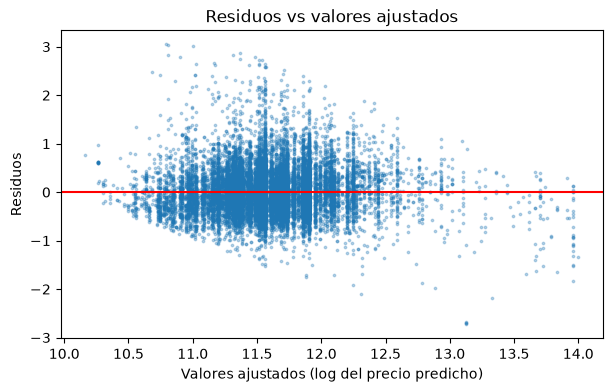

In [25]:
plt.figure(figsize=(7, 4))
plt.scatter(modelo_est.fittedvalues, modelo_est.resid, s=3, alpha=0.3)
plt.axhline(0, color="red")
plt.xlabel("Valores ajustados (log del precio predicho)")
plt.ylabel("Residuos")
plt.title("Residuos vs valores ajustados")
plt.show()

Shapiro-Wilk: ShapiroResult(statistic=np.float64(0.9470817587396966), pvalue=np.float64(4.192294171156635e-39))


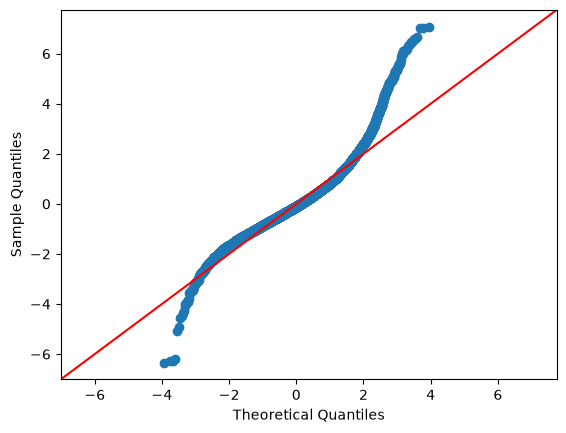

In [26]:
muestra = modelo_est.resid.sample(5000, random_state=1)
print("Shapiro-Wilk:", stats.shapiro(muestra))

sm.qqplot(modelo_est.resid, line="45", fit=True)
plt.show()

Los tres supuestos se comportan de forma parecida a la hipótesis C. No hay
multicolinealidad (todos los VIF cerca de 1). La dispersión de los residuos
es algo mayor en los extremos, por lo que la homocedasticidad se cumple de
forma aproximada. Los residuos no son normales (Shapiro-Wilk rechaza, con
una cola derecha de precios altos), pero dado el gran tamaño de la muestra
no creemos que invalide los resultados.

### Independencia de los errores

Muchas publicaciones pertenecen al mismo host: el 25 % de los hosts tiene 2 o
más publicaciones, y concentran el 62 % del total. Por eso sus errores
probablemente no sean independientes. Para ver si esto cambia las
conclusiones, repetimos ambos modelos agrupando los errores por host. Los
coeficientes de baños y de estadía siguen siendo significativos, pero el de
camas por huésped deja de serlo.

In [27]:
analisis_modelo["host_id"] = dataset_limpio["host_id"]

pub_por_host = analisis_modelo.groupby("host_id").size()

hosts_total = len(pub_por_host)
hosts_2mas = (pub_por_host >= 2).sum()

print(f"Hosts en la muestra: {hosts_total}")
print(f"Hosts con 2 o más publicaciones: {hosts_2mas} ({hosts_2mas / hosts_total:.1%})")
print(f"Publicaciones de esos hosts: {pub_por_host[pub_por_host >= 2].sum() / len(analisis_modelo):.1%}")

Hosts en la muestra: 12449
Hosts con 2 o más publicaciones: 3134 (25.2%)
Publicaciones de esos hosts: 62.3%


In [28]:
modelo2_host = smf.ols(modelo2.model.formula, data=analisis_modelo).fit(
    cov_type="cluster", cov_kwds={"groups": analisis_modelo["host_id"]})

datos_est = analisis_modelo.dropna(subset=["estadia"])
modelo_est_host = smf.ols(modelo_est.model.formula, data=datos_est).fit(
    cov_type="cluster", cov_kwds={"groups": datos_est["host_id"]})

clave_c = ["camas_por_huesped", "banos_por_huesped"]
clave_e = ["C(estadia)[T.media (7-29)]", "C(estadia)[T.larga (30+)]"]

pd.DataFrame({
    "p clásico": list(modelo2.pvalues[clave_c]) + list(modelo_est.pvalues[clave_e]),
    "p agrupado por host": list(modelo2_host.pvalues[clave_c]) + list(modelo_est_host.pvalues[clave_e]),
}, index=clave_c + clave_e)

,p clásico,p agrupado por host
camas_por_huesped,2.069069e-02,2.411576e-01
banos_por_huesped,7.402575e-43,6.364920e-11
C(estadia)[T.media (7-29)],5.785108e-79,1.102056e-32
C(estadia)[T.larga (30+)],2.008623e-54,1.323510e-30


### Conclusión de la hipótesis multivariada

Probamos que, a igual capacidad, tipo de alojamiento y barrio, los
alojamientos que exigen estadías más largas cobran menos por noche. Usamos
una regresión lineal múltiple sobre el logaritmo del precio (24.714
publicaciones, R² = 0,406), tomando la estadía corta como referencia:

- Estadía media (7 a 29 noches): cerca de 17 % menos por noche
  (intervalo de confianza del 95 %: entre 16 % y 19 % menos).
- Estadía larga (30 o más): cerca de 30 % menos (entre 27 % y 33 % menos).

Ambos efectos se mantienen significativos al agrupar los errores por host,
por lo que la hipótesis se confirma, y el descuento crece con la duración
de la estadía.

Limitaciones: es una asociación y no prueba que los hosts descuenten a
propósito; el grupo de estadía larga tiene solo 354 publicaciones, por lo que
su estimación es menos precisa; y los resultados dependen del criterio con
que excluimos datos incompletos y extremos.